# Lab01 - Sprint 1

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

sensors = pd.read_csv('ASE10.csv', sep = ';')

sensors.head(5)

,date,ASE_NO2,ASE_NO,ASE_CO,ASE_Ox,ASE_T,ASE_HR,ASE_PA,SUD3_NO2,SUD3_NO,QDP_NO,QDP_NO2,QDP_CO,Location
0,2021-10-20 14:00,29123.75000,43733.48438,40791.60938,29087.65625,23.253516,54.889016,1006.269444,11.2,3.5,15.6,22.7,0.139,SUD3
1,2021-10-20 15:00,29084.31434,42984.14706,40922.12408,29067.22335,22.838591,56.928588,1005.413194,17.8,6.2,20.7,27.1,0.148,SUD3
2,2021-10-20 16:00,29119.26563,42667.14063,40680.23438,29099.71875,22.751450,54.193586,1004.264236,13.3,2.1,23.9,30.2,0.178,SUD3
3,2021-10-20 17:00,29110.03125,42470.15625,40709.89063,29097.42188,22.614907,54.335088,1002.840972,13.4,1.1,12.6,28.7,0.129,SUD3
4,2021-10-20 18:00,29108.90165,42257.46048,40683.00092,29086.15717,21.929122,55.553496,1001.325000,11.8,0.9,8.3,32.6,0.122,SUD3


## Random Variable 02: Сигнал сенсора CO

### Description
Случайная величина 2 - сигнал электрохимического сенсора CO (`ASE_CO`), который снимается каждый час на автомобильном перекрестке. Вычислить его по формуле нельзя: значение зависит, в частности, от того, сколько машин проехало и как дует ветер, и к этому добавляется собственный шум прибора.

### EDA & Distribution


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3686 наблюдений.



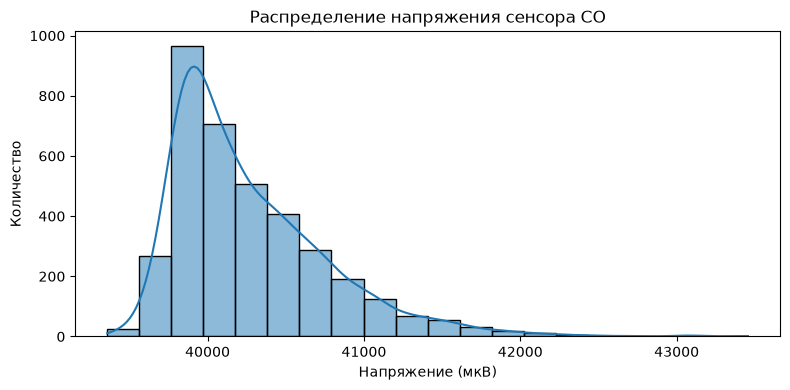

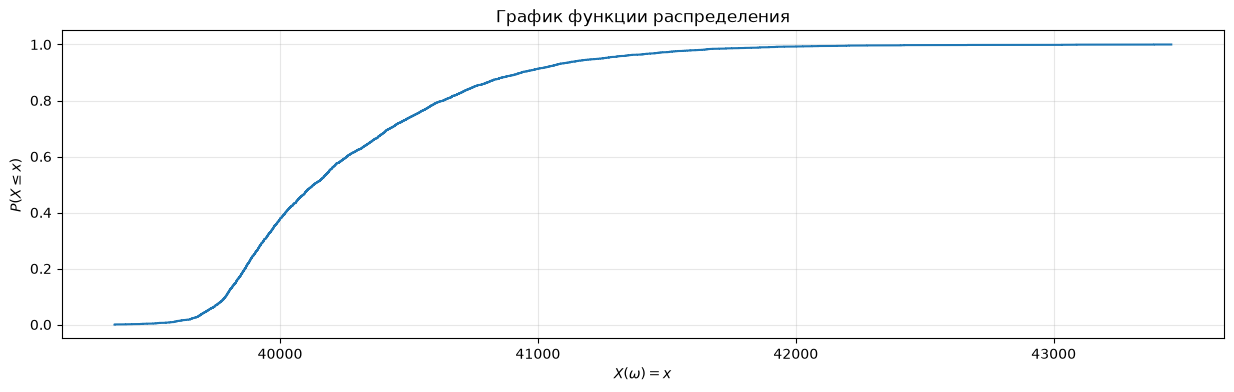


Сумма: 148429693.67587
Среднее: 40268.50072595497
Медиана: 40132.16728
Минимум: 39358.04688
Максимум: 43455.98346
Стандартное отклонение: 499.6717627929245
95-й перцентиль: 41247.7557475
Дисперсия: 249671.87053258857
Мода: 39752.20313


In [2]:
co_all = sensors['ASE_CO']
co = sensors['ASE_CO'].dropna()

print(f"\nРазмер данных до очистки: {co_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {co.shape[0]} наблюдений.\n")

co.head(5)

#распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=co,
    kde=True,
    ax=axes,
    bins = 20
)
axes.set_title("Распределение напряжения сенсора CO")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


#график ф-ции распределения
co_round = co.apply(lambda x: int(round(x)))
voltage = co_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/co.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_CO')
voltage['P'] = voltage ['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_CO'],voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

#остальные метрики
print(f"\nСумма:", co.sum())
print("Среднее:", co.mean())
print("Медиана:", co.median())
print("Минимум:", co.min())
print("Максимум:", co.max())
print("Стандартное отклонение:", co.std())
print("95-й перцентиль:", co.quantile(0.95))
print("Дисперсия:", co.var())
print("Мода:", co.mode().iloc[0])